# Chapter 29: Rules of Change, Unmasked

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** open up the shortcuts for finding a rate of change (the constant rule, the power rule, the product rule and the chain rule) and see the slow calculation each one replaces. A derivative rule is a receipt for work someone has already checked, so we will check the receipts.

The code cells are optional reading. Every result and every picture is shown right below the cell that makes it, so you can follow along without running anything. If you do want to run a cell, change a number and see what happens: nothing here can break.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

NAVY, TEAL, GOLD, PINK, INK, GREY = "#1f3a5f", "#1b8a8a", "#d9a21b", "#c0467a", "#222222", "#888888"

def g(x, digits=4):
    """Format a number without trailing zeros."""
    s = f"{x:.{digits}f}".rstrip("0").rstrip(".")
    return "0" if s in ("-0", "") else s

def par(x):
    """Wrap negative numbers in parentheses, for substitution chains."""
    s = g(x)
    return f"({s})" if s.startswith("-") else s

def new_fig(w=7, h=4):
    fig, ax = plt.subplots(figsize=(w, h))
    ax.grid(alpha=0.25)
    return fig, ax

## Demonstration 1: Constants have no change to report

**Question.** Adding 700 to $x^2$ lifts the whole graph. Does it change the slope anywhere?

$$\frac{d(x^2)}{dx} = 2x \qquad\qquad \frac{d(x^2 + 700)}{dx} = 2x$$

- $\frac{d}{dx}$ means "the rate of change as $x$ changes."
- $c$ is a constant: it stays fixed while $x$ moves, so its own rate of change is 0.

**Predict first:** at $x = 3$, what slope should both curves have?

We use the reader's starting values: $c = 700$ and the point $x = 1$.

In [2]:
c, x0 = 700, 1
h1 = x0**2
h2 = x0**2 + c
print(f"Height of x^2 at x = {x0}:       {x0}^2 = {h1}")
print(f"Height of x^2 + {c} at x = {x0}: {x0}^2 + {c} = {h2}")
print(f"Slope of x^2:         2({x0}) = {2*x0}")
print(f"Slope of x^2 + {c}:  2({x0}) + 0 = {2*x0 + 0}")
print(f"The constant's own rate: (c - c)/h = 0/h = 0")
print()
print("Other menu values (heights, slope):")
for cc in (700, 9, 0):
    for xx in (1, 3):
        print(f"  c = {cc:>3}, x = {xx}:  heights {xx**2} and {xx**2 + cc},  slope 2({xx}) + 0 = {2*xx}")

Height of x^2 at x = 1:       1^2 = 1
Height of x^2 + 700 at x = 1: 1^2 + 700 = 701
Slope of x^2:         2(1) = 2
Slope of x^2 + 700:  2(1) + 0 = 2
The constant's own rate: (c - c)/h = 0/h = 0

Other menu values (heights, slope):
  c = 700, x = 1:  heights 1 and 701,  slope 2(1) + 0 = 2
  c = 700, x = 3:  heights 9 and 709,  slope 2(3) + 0 = 6
  c =   9, x = 1:  heights 1 and 10,  slope 2(1) + 0 = 2
  c =   9, x = 3:  heights 9 and 18,  slope 2(3) + 0 = 6
  c =   0, x = 1:  heights 1 and 1,  slope 2(1) + 0 = 2
  c =   0, x = 3:  heights 9 and 9,  slope 2(3) + 0 = 6


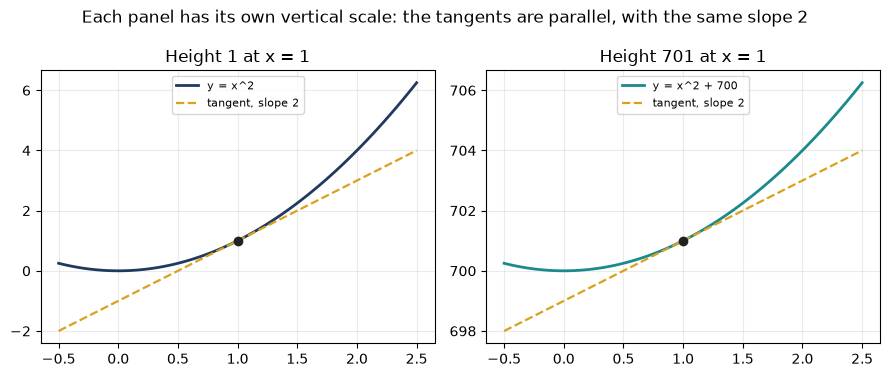

In [3]:
x0 = 1
xs = np.linspace(x0 - 1.5, x0 + 1.5, 121)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, shift, col in zip(axes, (0, 700), (NAVY, TEAL)):
    y0 = x0**2 + shift
    ax.plot(xs, xs**2 + shift, color=col, lw=2, label=f"y = x^2 + {shift}" if shift else "y = x^2")
    ax.plot(xs, y0 + 2*x0*(xs - x0), ls="dashed", color=GOLD, lw=1.6, label="tangent, slope 2")
    ax.plot([x0], [y0], "o", color=INK)
    ax.set_title(f"Height {y0} at x = {x0}")
    ax.grid(alpha=0.25); ax.legend(loc="upper center", fontsize=8)
fig.suptitle("Each panel has its own vertical scale: the tangents are parallel, with the same slope 2")
plt.tight_layout(); plt.show()

**What this shows.** The shifted curve is the same curve moved straight up, so its tangent at the dot is parallel to the original. When a formula has a fixed added amount, such as a flat fee, the fee changes the total but not how fast the total changes.

**Where it stops working.** $c$ must be constant with respect to $x$. If the added amount itself depended on $x$, it would contribute its own rate.

## Demonstration 2: The power pattern from the quotients

**Question.** At $x = 2$, which of $x$, $x^2$ and $x^3$ changes fastest, and where does $n x^{n-1}$ come from?

$$\frac{(2+h)^3 - 2^3}{h} = 3x^2 + 3xh + h^2 \quad (x = 2) \qquad\qquad \frac{d(x^n)}{dx} = n\,x^{n-1}$$

- $h$ is a small nonzero step away from $x = 2$.
- The quotient $\frac{(2+h)^n - 2^n}{h}$ is the average rate of change over that step.
- $n$ is a positive whole-number power.

**Predict first:** for $x^2$ with $h = 0.1$, the simplified quotient is $2x + h$. What do you expect?

Starting values: $x^3$ with $h = 0.1$.

In [4]:
x, n, h = 2, 3, 0.1
top = (x + h)**n - x**n
print(f"Change over the step: ({g(x+h)})^{n} - {x}^{n} = {g((x+h)**n)} - {x**n} = {g(top)}")
print(f"Quotient: {g(top)}/{g(h)} = {g(top/h)}")
print(f"Simplified: 3x^2 + 3xh + h^2 = 3({x}^2) + 3({x})({g(h)}) + {g(h)}^2 = {g(3*x**2)} + {g(3*x*h)} + {g(h**2)} = {g(3*x**2 + 3*x*h + h**2)}")
print(f"Power rule at x = {x}: n x^(n-1) = 3({x}^2) = {3*x**2}")
print()
print("All six menu states, quotient = [(2 + h)^n - 2^n]/h:")
for nn, name in ((1, "x"), (2, "x^2"), (3, "x^3")):
    row = []
    for hh in (0.5, 0.1):
        q = ((2 + hh)**nn - 2**nn)/hh
        row.append(f"h = {g(hh)}: {g(q)}")
    print(f"  {name:>3}:  " + ",   ".join(row) + f"   (power rule: {nn}(2^{nn-1}) = {nn*2**(nn-1)})")

Change over the step: (2.1)^3 - 2^3 = 9.261 - 8 = 1.261
Quotient: 1.261/0.1 = 12.61
Simplified: 3x^2 + 3xh + h^2 = 3(2^2) + 3(2)(0.1) + 0.1^2 = 12 + 0.6 + 0.01 = 12.61
Power rule at x = 2: n x^(n-1) = 3(2^2) = 12

All six menu states, quotient = [(2 + h)^n - 2^n]/h:
    x:  h = 0.5: 1,   h = 0.1: 1   (power rule: 1(2^0) = 1)
  x^2:  h = 0.5: 4.5,   h = 0.1: 4.1   (power rule: 2(2^1) = 4)
  x^3:  h = 0.5: 15.25,   h = 0.1: 12.61   (power rule: 3(2^2) = 12)


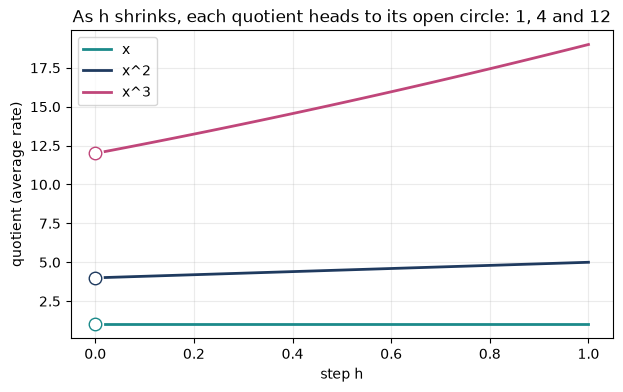

In [5]:
hs = np.linspace(0.02, 1.0, 100)
fig, ax = new_fig(7, 4)
for nn, name, col, lim in ((1, "x", TEAL, 1), (2, "x^2", NAVY, 4), (3, "x^3", PINK, 12)):
    ax.plot(hs, ((2 + hs)**nn - 2**nn)/hs, color=col, lw=2, label=name)
    ax.plot([0], [lim], "o", mfc="white", mec=col, ms=9, zorder=5)
ax.set_xlabel("step h"); ax.set_ylabel("quotient (average rate)")
ax.set_title("As h shrinks, each quotient heads to its open circle: 1, 4 and 12")
ax.legend(); plt.show()

**What this shows.** For each power the quotient simplifies to the rule's value plus terms that still contain $h$. Those terms fade as $h$ shrinks, so each curve heads to its open circle: 1, 4 and 12. The open circle is open because we never plug in $h = 0$ (that would be dividing by zero); we only watch where the numbers head.

**Where it stops working.** The rule is stated for positive whole-number powers. And the ranking at $x = 2$ (cube fastest) need not hold at every $x$.

## Demonstration 3: A product is not two isolated rates

**Question.** When both factors of $p(x) = x^2(x+1)$ change, where does the change in the product come from?

$$\frac{d[fg]}{dx} = f'g + fg' \qquad\qquad p(x) = x^2(x+1)$$

- $f = x^2$ is the width and $g = x + 1$ is the height, so the area is $fg$.
- $\Delta f$ and $\Delta g$ are the changes in each when $x$ grows by $h$. Here $\Delta g = h$.

**Predict first:** shrink $h$ from 0.5 to 0.1. Which shrinks faster compared with $h$: a strip or the corner?

Starting values: $x = 1$, $h = 0.5$.

In [6]:
x, h = 1, 0.5
f, gg = x**2, x + 1
df = (x + h)**2 - x**2
dg = h
strip1, strip2, corner = df*gg, f*dg, df*dg
total = strip1 + strip2 + corner
print(f"f and g at x = {x}: f = {x}^2 = {f}, g = {x} + 1 = {gg}")
print(f"Delta f = {g(x+h)}^2 - {x}^2 = {g((x+h)**2)} - {x**2} = {g(df)}")
print(f"Delta g = {g(dg)}")
print(f"Strip 1 (Delta f times g): {g(df)} x {gg} = {g(strip1)}")
print(f"Strip 2 (f times Delta g): {f} x {g(dg)} = {g(strip2)}")
print(f"Corner (Delta f times Delta g): {g(df)} x {g(dg)} = {g(corner)}")
print(f"Area change: {g(strip1)} + {g(strip2)} + {g(corner)} = {g(total)}")
print(f"Area change / h = {g(total)}/{g(h)} = {g(total/h)}")
print(f"Product rule p'(x) = (2x)(x + 1) + x^2(1) = {2*x*gg} + {f} = {2*x*gg + f}")
print(f"Corner share / h = {g(corner)}/{g(h)} = {g(corner/h)}")
print(f"The tempting but wrong f'g' would give 2 x 1 = {2*x*1}")
print()
print("All menu states:   x    h    area change   change/h   rule p'(x)   corner/h")
for xx in (1, 2):
    for hh in (1, 0.5, 0.1):
        p = lambda t: t**2*(t + 1)
        ch = p(xx + hh) - p(xx)
        dfx = (xx + hh)**2 - xx**2
        print(f"                  {xx}  {g(hh):>4}   {g(ch):>10}   {g(ch/hh):>8}   {g(2*xx*(xx+1) + xx**2):>9}   {g(dfx*hh/hh):>7}")

f and g at x = 1: f = 1^2 = 1, g = 1 + 1 = 2
Delta f = 1.5^2 - 1^2 = 2.25 - 1 = 1.25
Delta g = 0.5
Strip 1 (Delta f times g): 1.25 x 2 = 2.5
Strip 2 (f times Delta g): 1 x 0.5 = 0.5
Corner (Delta f times Delta g): 1.25 x 0.5 = 0.625
Area change: 2.5 + 0.5 + 0.625 = 3.625
Area change / h = 3.625/0.5 = 7.25
Product rule p'(x) = (2x)(x + 1) + x^2(1) = 4 + 1 = 5
Corner share / h = 0.625/0.5 = 1.25
The tempting but wrong f'g' would give 2 x 1 = 2

All menu states:   x    h    area change   change/h   rule p'(x)   corner/h
                  1     1           10         10           5         3
                  1   0.5        3.625       7.25           5      1.25
                  1   0.1        0.541       5.41           5      0.21
                  2     1           24         24          16         5
                  2   0.5        9.875      19.75          16      2.25
                  2   0.1        1.671      16.71          16      0.41


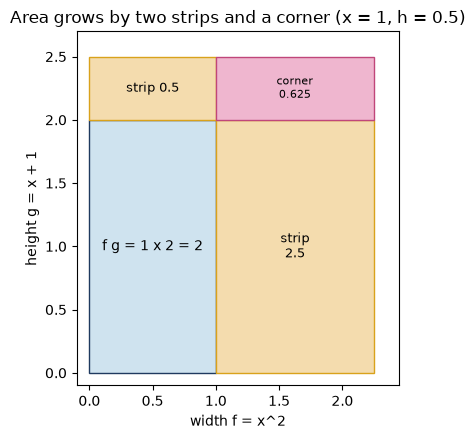

In [7]:
x, h = 1, 0.5
f, gg = x**2, x + 1
df = (x + h)**2 - x**2
fig, ax = plt.subplots(figsize=(6.5, 4.6))
from matplotlib.patches import Rectangle
ax.add_patch(Rectangle((0, 0), f, gg, fc="#cfe3ef", ec=NAVY))
ax.add_patch(Rectangle((f, 0), df, gg, fc="#f4dcae", ec=GOLD))
ax.add_patch(Rectangle((0, gg), f, h, fc="#f4dcae", ec=GOLD))
ax.add_patch(Rectangle((f, gg), df, h, fc="#efb6cf", ec=PINK))
ax.text(f/2, gg/2, f"f g = {f} x {gg} = {f*gg}", ha="center", va="center")
ax.text(f + df/2, gg/2, f"strip\n{g(df*gg)}", ha="center", va="center", fontsize=9)
ax.text(f/2, gg + h/2, f"strip {g(f*h)}", ha="center", va="center", fontsize=9)
ax.text(f + df/2, gg + h/2, f"corner\n{g(df*h)}", ha="center", va="center", fontsize=8)
ax.set_xlim(-0.1, f + df + 0.2); ax.set_ylim(-0.1, gg + h + 0.2); ax.set_aspect("equal")
ax.set_xlabel("width f = x^2"); ax.set_ylabel("height g = x + 1")
ax.set_title("Area grows by two strips and a corner (x = 1, h = 0.5)")
plt.show()

**What this shows.** The area grows by two strips and a corner. Divided by $h$, the strips head toward $f'g$ and $fg'$, while the corner, a change times a change, fades away as $h$ shrinks. That is why the rule is $f'g + fg'$ and never $f'g'$. When two changing quantities multiply, such as a price and a quantity, count both strips.

**Where it stops working.** Both factors must be differentiable, as in the chapter. The picture motivates the rule; a proof is what makes it a theorem.

## Demonstration 4: Check the chain rule at one point

**Question.** Does the chain rule's 6 for $q(t) = (3t+1)^2$ at $t = 0$ match the slow quotients?

$$q'(0) = 6(1) = 6 \qquad\qquad \frac{q(h) - q(0)}{h} = 6 + 9h$$

- The inside is $u = 3t + 1$, with rate 3. The outside squares $u$, with rate $2u$. At $t = 0$, $u = 1$.
- $h$ is a small nonzero step from $t = 0$.

**Predict first:** a rule that forgets the inside rate claims 2 instead of 6. How far off will it look against the quotients?

Starting values: $h = 0.01$, checking the chain rule.

In [8]:
h = 0.01
qh = (3*h + 1)**2
quot = (qh - 1)/h
print(f"q(h) = (3({g(h)}) + 1)^2 = ({g(3*h + 1)})^2 = {g(qh, 6)}")
print(f"Difference quotient: ({g(qh, 6)} - 1)/{g(h)} = {g(quot, 6)}")
print(f"Simplified: 6 + 9({g(h)}) = {g(6 + 9*h, 6)}")
print(f"Rule's claimed q'(0): 2(1)(3) = 6")
print("Quotients approach 6 from the right (above) and the left (below): the rule passes.")
print()
print("All menu steps:")
for hh in (0.01, -0.01, 0.1, -0.1):
    qq = ((3*hh + 1)**2 - 1)/hh
    print(f"  h = {par(hh):>7}: ((3({g(hh)}) + 1)^2 - 1)/{par(hh)} = {g(qq, 6)} = 6 + 9({g(hh) if hh > 0 else "-" + g(-hh)})")
print()
print("Rule that forgets the inside rate claims 2(1) = 2.")
print(f"At h = {g(h)} the quotient is {g(quot,6)}, so it misses by {g(quot - 2, 6)}.")

q(h) = (3(0.01) + 1)^2 = (1.03)^2 = 1.0609
Difference quotient: (1.0609 - 1)/0.01 = 6.09
Simplified: 6 + 9(0.01) = 6.09
Rule's claimed q'(0): 2(1)(3) = 6
Quotients approach 6 from the right (above) and the left (below): the rule passes.

All menu steps:
  h =    0.01: ((3(0.01) + 1)^2 - 1)/0.01 = 6.09 = 6 + 9(0.01)
  h = (-0.01): ((3(-0.01) + 1)^2 - 1)/(-0.01) = 5.91 = 6 + 9(-0.01)
  h =     0.1: ((3(0.1) + 1)^2 - 1)/0.1 = 6.9 = 6 + 9(0.1)
  h =  (-0.1): ((3(-0.1) + 1)^2 - 1)/(-0.1) = 5.1 = 6 + 9(-0.1)

Rule that forgets the inside rate claims 2(1) = 2.
At h = 0.01 the quotient is 6.09, so it misses by 4.09.


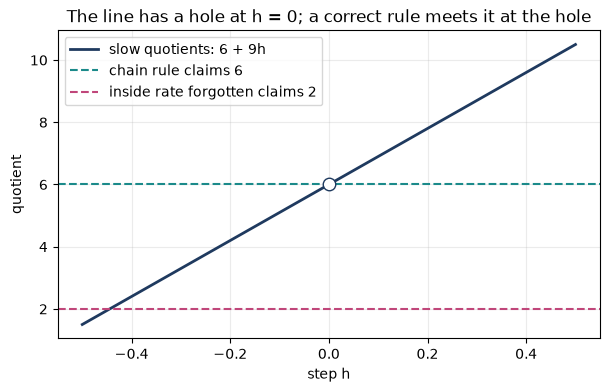

In [9]:
hs = np.concatenate([np.linspace(-0.5, -0.005, 60), np.linspace(0.005, 0.5, 60)])
fig, ax = new_fig(7, 4)
ax.plot(hs, ((3*hs + 1)**2 - 1)/hs, color=NAVY, lw=2, label="slow quotients: 6 + 9h")
ax.plot([0], [6], "o", mfc="white", mec=NAVY, ms=9, zorder=5)
ax.axhline(6, ls="dashed", color=TEAL, label="chain rule claims 6")
ax.axhline(2, ls="dashed", color=PINK, label="inside rate forgotten claims 2")
ax.set_xlabel("step h"); ax.set_ylabel("quotient")
ax.set_title("The line has a hole at h = 0; a correct rule meets it at the hole")
ax.legend(); plt.show()

**What this shows.** For every nonzero $h$ the quotient is $6 + 9h$, a line with a hole at $h = 0$. The chain rule's claim of 6 meets the line exactly at the hole. The rule that forgets the inside rate claims 2 and misses at once. After using any rule, test it at one point with a small positive and a small negative step.

**Where it stops working.** One spot check at one input can expose a wrong rule, but it does not prove the chain rule everywhere.

## Practice

Try each one on paper first, then open the answer to compare.

**1.** What is the slope of $x^2 + 700$ at $x = 5$?

<details><summary>Show answer</summary>

The constant adds a rate of 0, so the slope is $2(5) + 0 = 10$. That is the same as the slope of $x^2$ at $x = 5$.

</details>

**2.** For $x^3$ at $x = 2$ with $h = 1$, what is the quotient?

<details><summary>Show answer</summary>

$\dfrac{(2+1)^3 - 2^3}{1} = 27 - 8 = 19$. Check with the simplified form: $3(4) + 3(2)(1) + 1 = 12 + 6 + 1 = 19$.

</details>

**3.** Using the product rule, what is $p'(1)$ for $p(x) = x^2(x+1)$?

<details><summary>Show answer</summary>

$p'(1) = (2 \cdot 1)(1 + 1) + 1^2(1) = 4 + 1 = 5$. Check by expanding: $p(x) = x^3 + x^2$, so $p'(1) = 3(1)^2 + 2(1) = 5$.

</details>

**4.** What is the chain-rule quotient at $h = 0.1$ for $q(t) = (3t+1)^2$?

<details><summary>Show answer</summary>

$6 + 9(0.1) = 6.9$. Check: $\dfrac{1.3^2 - 1}{0.1} = \dfrac{0.69}{0.1} = 6.9$.

</details>